
# IMF Poland 2023: LLM-Based Financial Report Analysis




In [1]:
!pip -q install pypdf tiktoken transformers sentencepiece sentence-transformers faiss-cpu
from google.colab import files
from pypdf import PdfReader

uploaded = files.upload()

pdf_path = next(iter(uploaded))
reader = PdfReader(pdf_path)

pages = []

for page_number, page in enumerate(reader.pages, start=1):
    pages.append({
        "page": page_number,
        "text": page.extract_text() or ""
    })

full_text = "\n".join(page["text"] for page in pages)

print("Total PDF Pages:", len(pages))
print("Total Characters:", len(full_text))
print("\nText Sample:\n")
print(full_text[:1000])

Saving null-002.2023.issue-189-en.pdf to null-002.2023.issue-189-en.pdf
Total PDF Pages: 87
Total Characters: 217023

Text Sample:


 
© 2023 International Monetary Fund 
IMF Country Report No. 23/189 
 
REPUBLIC OF POLAND 
2023 ARTICLE IV CONSULTATION—PRESS RELEASE; 
AND STAFF REPORT 
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions 
with members, usually every year. In the context of the 2023 Article IV consultation with 
the Republic of Poland, the following documents have been released and are included in 
this package: 
 
• A Press Release. 
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s 
consideration on a lapse-of-time basis, following discussions that ended on 
March 24, 2023, with the officials of the Republic of Poland on economic 
developments and policies. Based on information available at the time of these 
discussions, the staff report was completed on May 10, 2023. 
• An Informational Annex prepare


## Text Preprocessing




In [2]:
import re

def clean_text(text):
    text = re.sub(
        r'©\s*International Monetary Fund.*?Not for Redistribution',
        ' ', text, flags=re.I
    )

    text = re.sub(
        r'©\s*2023 International Monetary Fund',
        ' ', text, flags=re.I
    )

    text = re.sub(r'[ \t]+', ' ', text)
    text = re.sub(r'\n{3,}', '\n\n', text)

    return text.strip()


cleaned_pages = [
    {"page": page["page"], "text": clean_text(page["text"])}
    for page in pages
]

cleaned_text = "\n\n".join(
    page["text"] for page in cleaned_pages
)

print("Original Characters:", len(full_text))
print("Cleaned Characters:", len(cleaned_text))
print("\nCleaned Text Sample:\n")
print(cleaned_text[:800])

Original Characters: 217023
Cleaned Characters: 211388

Cleaned Text Sample:



IMF Country Report No. 23/189 
 
REPUBLIC OF POLAND 
2023 ARTICLE IV CONSULTATION—PRESS RELEASE; 
AND STAFF REPORT 
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions 
with members, usually every year. In the context of the 2023 Article IV consultation with 
the Republic of Poland, the following documents have been released and are included in 
this package: 
 
• A Press Release. 
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s 
consideration on a lapse-of-time basis, following discussions that ended on 
March 24, 2023, with the officials of the Republic of Poland on economic 
developments and policies. Based on information available at the time of these 
discussions, the staff report was completed on May 10, 2023. 
•


## Clear Text Chunks

In [3]:
import tiktoken

encoding = tiktoken.get_encoding("cl100k_base")

chunk_size = 400
overlap = 50

chunks = []

for page in cleaned_pages:

    tokens = encoding.encode(page["text"])

    for start in range(0, len(tokens), chunk_size - overlap):

        chunk_tokens = tokens[start:start + chunk_size]

        if not chunk_tokens:
            continue

        chunks.append({
            "chunk_id": len(chunks),
            "page": page["page"],
            "text": encoding.decode(chunk_tokens),
            "token_count": len(chunk_tokens)
        })

        if start + chunk_size >= len(tokens):
            break

print("Total Chunks:", len(chunks))
print("Chunk Size:", chunk_size)
print("Overlap:", overlap)

print("\nFirst Chunk:\n")
print(chunks[0]["text"][:600])

Total Chunks: 201
Chunk Size: 400
Overlap: 50

First Chunk:

IMF Country Report No. 23/189 
 
REPUBLIC OF POLAND 
2023 ARTICLE IV CONSULTATION—PRESS RELEASE; 
AND STAFF REPORT 
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions 
with members, usually every year. In the context of the 2023 Article IV consultation with 
the Republic of Poland, the following documents have been released and are included in 
this package: 
 
• A Press Release. 
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s 
consideration on a lapse-of-time basis, following discussions that ended on 
March 24, 2023, wit


In [4]:
import json

with open("poland_cleaned_text.txt", "w", encoding="utf-8") as f:
    f.write(cleaned_text)

with open("poland_chunks.json", "w", encoding="utf-8") as f:
    json.dump(chunks, f, indent=2, ensure_ascii=False)

print("Cleaned text saved.")
print("Text chunks saved.")

Cleaned text saved.
Text chunks saved.


## Load FLAN-T5 Base

In [5]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/flan-t5-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

def summarizer(prompt, max_new_tokens=120):
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False
    )

    return tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

print("Loaded Model:", model_name)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loaded Model: google/flan-t5-base


In [6]:
# Test the model using a paragraph from the IMF report

test_text = next(
    page["text"]
    for page in cleaned_pages
    if page["page"] == 35
)

test_text = test_text.split("STAFF APPRAISAL", 1)[-1][:1200]

prompt = f"""
Summarise the main economic findings in this passage.
Use only the supplied information.

Text:
{test_text}

Summary:
"""

llm_summary = summarizer(prompt)

print("FLAN-T5 Base Summary:\n")
print(llm_summary)

FLAN-T5 Base Summary:

The Polish economy has slowed sharply in the past few years, with a slowdown in the past few years.


## Identifying the headings

In [7]:
section_headings = [
    "OUTLOOK AND RISKS",
    "A. Fiscal Policies",
    "B. Monetary and Exchange Rate Policies",
    "C. Financial Sector Policies",
    "D. Energy and Climate Policies",
    "E. Labor Markets and Refugees",
    "STAFF APPRAISAL"
]

# Use main report pages, excluding the table of contents
report_text = "\n".join(
    page["text"] for page in cleaned_pages
    if 15 <= page["page"] <= 40
)

section_texts = {}

for i, heading in enumerate(section_headings):

    start = report_text.find(heading)

    if start == -1:
        print("Heading not found:", heading)
        continue

    start += len(heading)

    if i < len(section_headings) - 1:
        end = report_text.find(section_headings[i + 1], start)
    else:
        end = report_text.find("Figure 15.", start)

    if end == -1:
        print("End heading not found:", heading)
        continue

    name = heading.replace("STAFF APPRAISAL", "Staff Appraisal")
    name = name.replace("OUTLOOK AND RISKS", "Outlook and Risks")
    name = name[3:] if name[:3] in ["A. ", "B. ", "C. ", "D. ", "E. "] else name

    section_texts[name] = report_text[start:end].strip()

for section, text in section_texts.items():
    print(section, "—", len(text.split()), "words")

print("\nTotal sections:", len(section_texts))

Outlook and Risks — 1060 words
Fiscal Policies — 2401 words
Monetary and Exchange Rate Policies — 1048 words
Financial Sector Policies — 2028 words
Energy and Climate Policies — 787 words
Labor Markets and Refugees — 245 words
Staff Appraisal — 646 words

Total sections: 7


## Automated LLM Section Summarisation

In [8]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## Source based summarisation

In [9]:
import re
import numpy as np

section_summaries = {}
section_evidence = {}

for section, text in section_texts.items():

    sentences = re.split(r'(?<=[.!?])\s+', text)

    sentences = [
        " ".join(s.split())
        for s in sentences
        if 50 < len(s) < 300
    ]

    sentences = [
        s for s in sentences
        if not any(word in s.lower() for word in [
            "figure ", "table ", "source:",
            "international monetary fund"
        ])
    ]

    if not sentences:
        section_summaries[section] = ""
        section_evidence[section] = []
        continue

    vectors = embedding_model.encode(
        sentences,
        normalize_embeddings=True
    )

    scores = vectors @ vectors.mean(axis=0)

    selected = sorted(
        np.argsort(scores)[-3:]
    )

    evidence = [sentences[i] for i in selected]

    # Keep selected evidence within 100 words
    summary_sentences = []
    word_count = 0

    for sentence in evidence:
        words = len(sentence.split())

        if word_count + words < 100:
            summary_sentences.append(sentence)
            word_count += words

    summary = " ".join(summary_sentences)

    section_summaries[section] = summary
    section_evidence[section] = evidence

    print(f"\n{section}")
    print(summary)
    print("Word Count:", len(summary.split()))


Outlook and Risks
A significant growth slowdown is projected in 2023, with a risk of recession. Fading energy price shocks and slowing domestic demand will narrow the deficit in 2023, while sectoral saving- investment balances are projected to improve as household saving increases with real wage recovery and lower inventory levels moderate gross corporate investment. The authorities projected a smaller current account deficit than staff over the medium term, in line with historical trends, arguing that Poland’s trade balance would continue to improve as it became more integrated into global value chains.
Word Count: 89

Fiscal Policies
With a smaller fiscal cost of discretionary fiscal measures in 2023 relative to 2022… … the fiscal impulse is expected to be mildly contractionary, similar to European peers’ average. To accommodate additional defense expenditures, the authorities should find offsetting savings to prevent debt from increasing over the medium term. Poland: Medium-Term Pr

In [10]:
executive_bullets = []

for section, summary in section_summaries.items():

    if summary.strip():

        finding = section_evidence[section][0]

        executive_bullets.append({
            "Section": section,
            "Key Finding": finding,
            "Verification": "Pending"
        })

print("IMF POLAND 2023 — EXECUTIVE SUMMARY\n")

for item in executive_bullets:
    print(f"• {item['Section']}: {item['Key Finding']}\n")

IMF POLAND 2023 — EXECUTIVE SUMMARY

• Outlook and Risks: A significant growth slowdown is projected in 2023, with a risk of recession.

• Fiscal Policies: With a smaller fiscal cost of discretionary fiscal measures in 2023 relative to 2022… … the fiscal impulse is expected to be mildly contractionary, similar to European peers’ average.

• Monetary and Exchange Rate Policies: Headline inflation is projected to approach the tolerance range around the target only at the end of 2025… …with staff projecting a slower core disinflation than the NBP.

• Financial Sector Policies: Banks that fail to issue eligible debt would need to meet the requirement with own funds, which would erode excess capital buffers and weigh on their ability to expand credit.

• Energy and Climate Policies: An increased use of renewables would reduce carbon intensity while preserving Poland’s low energy import dependency.

• Labor Markets and Refugees: Measures to grant Ukrainian refugees access to the Polish labor

## Generated Summaries

In [11]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

evaluation = []

for section, summary in section_summaries.items():

    source = section_texts[section]

    source_vector = embedding_model.encode(
        source[:3000],
        normalize_embeddings=True
    )

    summary_vector = embedding_model.encode(
        summary,
        normalize_embeddings=True
    )

    similarity = float(
        np.dot(source_vector, summary_vector)
    )

    evaluation.append({
        "Section": section,
        "Word Count": len(summary.split()),
        "Under 100 Words": len(summary.split()) < 100,
        "Semantic Similarity": round(similarity, 3),
        "Human Verification": "Pending"
    })

evaluation_df = pd.DataFrame(evaluation)

display(evaluation_df)

print("Total Sections:", len(evaluation_df))
print(
    "All Under 100 Words:",
    evaluation_df["Under 100 Words"].all()
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,Section,Word Count,Under 100 Words,Semantic Similarity,Human Verification
0,Outlook and Risks,89,True,0.637,Pending
1,Fiscal Policies,69,True,0.749,Pending
2,Monetary and Exchange Rate Policies,90,True,0.693,Pending
3,Financial Sector Policies,58,True,0.491,Pending
4,Energy and Climate Policies,93,True,0.878,Pending
5,Labor Markets and Refugees,93,True,0.896,Pending
6,Staff Appraisal,34,True,0.641,Pending


Total Sections: 7
All Under 100 Words: True


## Saving results

In [12]:
import json

with open("poland_section_summaries.json", "w", encoding="utf-8") as f:
    json.dump(section_summaries, f, indent=4, ensure_ascii=False)

with open("poland_executive_summary.json", "w", encoding="utf-8") as f:
    json.dump(executive_bullets, f, indent=4, ensure_ascii=False)

evaluation_df.to_csv(
    "poland_summary_evaluation.csv",
    index=False
)

print("\nTotal sections:", len(section_summaries))
print("Executive bullets:", len(executive_bullets))
print("Evaluation records:", len(evaluation_df))

Task 1 files saved successfully.

Total sections: 7
Executive bullets: 7
Evaluation records: 7


## **Financial Theme Analysis and Information Extraction**

,Theme,Mentions
0,Inflation,176
1,Interest & Credit,109
3,Banking,72
2,Housing,45
4,Sovereign Debt,34
5,Labour Market,32
6,Financial Risk,9


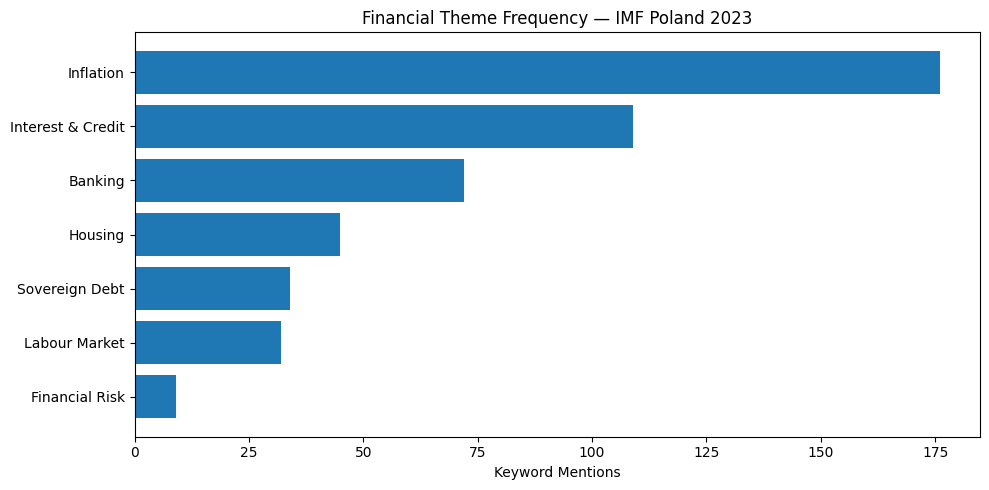

In [13]:
import re
import pandas as pd
import matplotlib.pyplot as plt

themes = {
    "Inflation": ["inflation", "consumer prices", "cpi"],
    "Interest & Credit": ["interest rate", "credit", "lending"],
    "Housing": ["housing", "real estate", "mortgage"],
    "Banking": ["bank", "capital adequacy", "liquidity"],
    "Sovereign Debt": ["public debt", "government debt", "sovereign debt"],
    "Labour Market": ["employment", "unemployment", "wages"],
    "Financial Risk": ["financial stability", "systemic risk", "financial risk"]
}

counts = {}

for theme, keywords in themes.items():
    counts[theme] = sum(
        len(re.findall(
            r"\b" + re.escape(word) + r"\b",
            cleaned_text,
            flags=re.I
        ))
        for word in keywords
    )

theme_df = pd.DataFrame(
    counts.items(),
    columns=["Theme", "Mentions"]
).sort_values("Mentions", ascending=False)

display(theme_df)

plt.figure(figsize=(10, 5))
plt.barh(theme_df["Theme"], theme_df["Mentions"])
plt.gca().invert_yaxis()

plt.title("Financial Theme Frequency — IMF Poland 2023")
plt.xlabel("Keyword Mentions")
plt.tight_layout()

plt.savefig("poland_financial_themes.png", dpi=300)
plt.show()

theme_df.to_csv("poland_theme_counts.csv", index=False)

## Extract Strengths And Vulnerabilities

In [32]:
keywords = {
    "Strengths": [
        "resilient", "well capitalized", "stable",
        "recovery", "adequate reserves"
    ],
    "Vulnerabilities": [
        "high inflation", "risk", "uncertainty",
        "slowdown", "legal challenges"
    ]
}

for category, terms in keywords.items():

    print(f"\n {category.upper()}:")

    findings = []

    for page in cleaned_pages:

        sentences = re.split(
            r'(?<=[.!?])\s+',
            page["text"]
        )

        for sentence in sentences:

            sentence = " ".join(sentence.split())

            if (
                50 < len(sentence) < 350
                and any(term in sentence.lower() for term in terms)
                and "source:" not in sentence.lower()
            ):
                findings.append((page["page"], sentence))

    for page_number, sentence in findings[:7]:
        print(f"PDF Page {page_number}: {sentence}\n")


 STRENGTHS:
PDF Page 3: Following a rapid recovery from the pandemic, the Polish economy grew 5.1 percent in 2022, though the economy slowed considerably later in the year.

PDF Page 3: Bank asset quality has remained stable, and sector-wide capital adequacy levels remain significantly above regulatory requirements.

PDF Page 4: 2 Executive Board Assessment2 After the rapid recovery from the pandemic, the Polish economy has weakened significantly amid still-high inflation.

PDF Page 4: While the banking sector has remained stable, there are significant legal and regulatory challenges.

PDF Page 15: Cooperative banks – representing 7 percent of system assets – continued a gradual consolidation process, remained well capitalized, and significantly increased profits, which permitted additional contributions to their IPSs in 2022.

PDF Page 16: Fading energy price shocks and slowing domestic demand will narrow the deficit in 2023, while sectoral saving- investment balances are projected t

## Financial indicator evidence

In [33]:
indicators = {
    "GDP Growth": ["gdp growth", "growth of 0.3"],
    "Inflation": ["headline inflation", "average inflation"],
    "Policy Rate": ["policy rate", "reference rate"],
    "Non-performing Loans": ["nonperforming loans", "non-performing loans", "npls"],
    "Unemployment": ["unemployment rate", "unemployment"],
    "Tier 1 Capital": ["tier 1", "tier i"]
}

for indicator, terms in indicators.items():

    print(f"\n{indicator.upper()}:")

    found = 0

    for page in cleaned_pages:

        text = " ".join(page["text"].split())

        for term in terms:
            pos = text.lower().find(term)

            if pos != -1:
                print(f"PDF Page {page['page']}:")
                print(text[max(0, pos-100):pos+250], "\n")
                found += 1
                break

        if found >= 3:
            break

    if found == 0:
        print("No matching passage found.")


GDP GROWTH:
PDF Page 11:
rly, and 39 percent are women of working age. Note: Contributions to growth may not sum to headline GDP growth due to statistical discrepancies. Sources: Statistics Poland; United Nations High Commissioner for Refugees; Powszechny Elektroniczny System Ewidencji Ludnosci (PESEL); and IMF staff calculations. 80 90 100 110 120 130 140 150 160 Jan-18 J 

PDF Page 17:
3 2028Q1 2028Q3 Econ active pop Unemployment Avg hours worked Foreign workers Capital TFP Potential GDP growth Contributions to Potential Growth (Percent) Sources: IMF staff calculations. 0 1 2 3 4 5 6 7 8 9 10 Jan-19 Jun-19 Nov-19 Apr-20 Sep-20 Feb-21 Jul-21 Dec-21 May-22 Oct-22 Exports to Ukraine Imports from Ukraine Bilateral Trade with Ukraine  

PDF Page 22:
k.org/en/country/poland/publication/poland-public-finance-review 2023 2024 2025 2026 2027 2028 Real GDP growth (percent) Baseline 0.3 2.4 3.7 3.4 3.1 3.1 Adjustment 0.0 2.3 3.4 3.9 3.2 3.1 Core inflation (percent, period avg) Baseline 11.2 7.

In [34]:
import json

financial_data = {
    "country_name": "Poland",
    "report_year": 2023,
    "gdp_growth_forecast_pct": 0.3,
    "headline_inflation_rate_pct": 12.4,
    "central_bank_policy_rate_pct": 6.75,
    "non_performing_loan_ratio": 2.6,
    "unemployment_rate_pct": 3.2,
    "tier_1_capital_ratio": 15.2,

    "historical_data": {
        "2021": {"gdp_growth": 6.9, "average_inflation": 5.1, "unemployment": 3.4},
        "2022": {"gdp_growth": 5.1, "average_inflation": 14.4, "unemployment": 2.9},
        "2023": {"gdp_growth": 0.3, "average_inflation": 12.4, "unemployment": 3.2},
        "2024": {"gdp_growth": 2.4, "average_inflation": 6.2, "unemployment": 3.5},
        "2025": {"gdp_growth": 3.7, "average_inflation": 4.2, "unemployment": 3.4}
    },

    "2023_values_are_projections": True,
    "policy_rate_source": "NBP monetary policy rate paused at 6.75% in October 2022",
    "banking_indicators_year": "2022 Q3"
}

with open("poland_financial_data.json", "w", encoding="utf-8") as f:
    json.dump(financial_data, f, indent=4)



## Financial data validation and visual comparision

Financial Indicator Validation


,Indicator,Value,Status
0,gdp_growth_forecast_pct,0.30,Available
1,headline_inflation_rate_pct,12.40,Available
2,central_bank_policy_rate_pct,6.75,Available
3,non_performing_loan_ratio,2.60,Available
4,unemployment_rate_pct,3.20,Available
5,tier_1_capital_ratio,15.20,Available



HISTORICAL AND PROJECTED INDICATORS


,gdp_growth,average_inflation,unemployment
Year,,,
2021,6.9,5.1,3.4
2022,5.1,14.4,2.9
2023,0.3,12.4,3.2
2024,2.4,6.2,3.5
2025,3.7,4.2,3.4


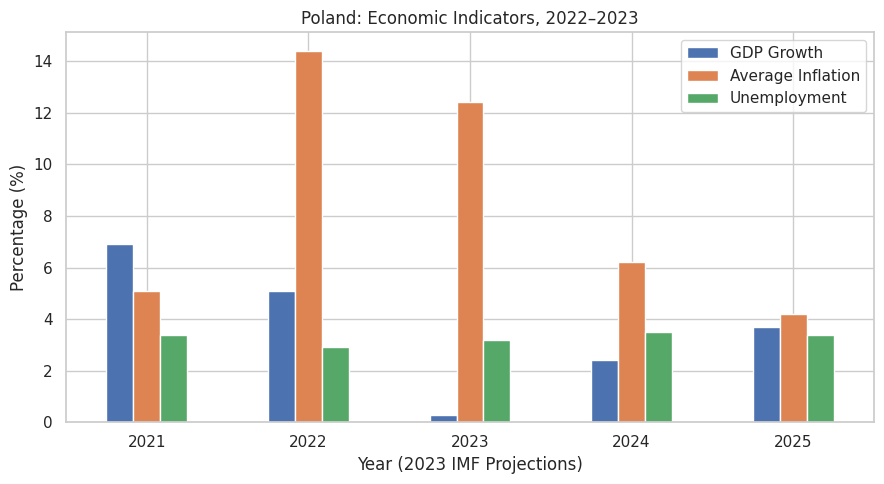

In [35]:
fields = [
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

validation_df = pd.DataFrame({
    "Indicator": fields,
    "Value": [financial_data.get(field) for field in fields]
})

validation_df["Status"] = validation_df["Value"].apply(
    lambda x: "Missing" if pd.isna(x) else "Available"
)

print("Financial Indicator Validation")
display(validation_df)

historical_df = pd.DataFrame.from_dict(
    financial_data["historical_data"],
    orient="index"
)

historical_df.index.name = "Year"

print("\nHistorical And Projected Indicators")
display(historical_df)

historical_df.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Poland: Economic Indicators, 2022–2023")
plt.ylabel("Percentage (%)")
plt.xlabel("Year (2023 IMF Projections)")
plt.xticks(rotation=0)
plt.legend(["GDP Growth", "Average Inflation", "Unemployment"])
plt.tight_layout()
plt.show()

In [18]:
theme_df.to_csv("poland_theme_counts.csv", index=False)

validation_df.to_csv(
    "poland_financial_validation.csv",
    index=False
)

historical_df.to_csv(
    "poland_historical_indicators.csv"
)

with open("poland_financial_data.json", "w", encoding="utf-8") as f:
    json.dump(financial_data, f, indent=4)

print("Financial theme counts saved.")
print("Financial indicators saved.")
print("Validation and historical data saved.")

Task 2 completed.
Financial theme counts saved.
Financial indicators saved.
Validation and historical data saved.


## **Retrieval-Augmented Generation (RAG)**

In [19]:
import numpy as np
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

texts = [chunk["text"] for chunk in chunks]

embeddings = embedding_model.encode(
    texts,
    convert_to_numpy=True,
    show_progress_bar=True
).astype("float32")

print("Total Text Chunks:", len(texts))
print("Embeddings Shape:", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Total Text Chunks: 201
Embeddings Shape: (201, 384)


In [20]:
import faiss

index = faiss.IndexFlatL2(embeddings.shape[1])

index.add(embeddings)

faiss.write_index(
    index,
    "poland_faiss.index"
)

print("FAISS Index Created")
print("Indexed Chunks:", index.ntotal)
print("Vector Dimensions:", embeddings.shape[1])

FAISS Index Created
Indexed Chunks: 201
Vector Dimensions: 384


In [21]:
# Semantic retrieval with PDF page references

def retrieve_passages(question, top_k=3):

    question_vector = embedding_model.encode(
        [question]
    ).astype("float32")

    distances, indices = index.search(
        question_vector,
        top_k
    )

    results = []

    for rank, chunk_id in enumerate(indices[0], start=1):

        chunk = chunks[int(chunk_id)]

        results.append({
            "Rank": rank,
            "PDF Page": chunk["page"],
            "Text": chunk["text"],
            "Distance": round(float(distances[0][rank - 1]), 3)
        })

    return results


# Test retrieval
question = "What are the main financial risks facing Poland?"

retrieved = retrieve_passages(question)

for result in retrieved:
    print(f"\nRank: {result['Rank']}")
    print(f"PDF Page: {result['PDF Page']}")
    print(f"Distance: {result['Distance']}")
    print(result["Text"][:500])


Rank: 1
PDF Page: 42
Distance: 0.731
REPUBLIC OF POLAND 
36 INTERNATIONAL MONETARY FUND 
Figure 20. Poland: Banking Sector Developments 
Banks are extremely liquid… …though deposit growth moderated after pandemic liquidity programs ended. 
 
 
 
…and banks flush with domestic liquidity have little need 
for external funding… …including from parent banks. 
 
 
 
Open FX positions have declined over time. Banks took on significant new amounts of government and guaranteed debt during the pandemic. 
 
 
 
Sources: NBP; Statistics Polan

Rank: 2
PDF Page: 73
Distance: 0.773
REPUBLIC OF POLAND 
INTERNATIONAL MONETARY FUND 67 
Annex IX. Risk Assessment Matrix1 
Source of Risk Relative 
Likelihood 
Impact if Realized Policy Response 
Conjunctural and Structural Risks 
Intensification of regional 
conflict(s). Escalation of Russia’s 
war in Ukraine or other regional 
conflicts and resulting economic 
sanctions disrupt trade (e.g., 
energy, food, tourism, and/or 
critical supply chain component

In [22]:
import re
import numpy as np

def rag_answer(question):

    passages = retrieve_passages(question, top_k=5)
    evidence = []

    for passage in passages:
        text = passage["Text"]
        text = re.sub(r"\bREPUBLIC OF POLAND\b", " ", text)
        text = re.sub(r"\bINTERNATIONAL MONETARY FUND\b", " ", text)
        text = re.sub(r"\bFigure\s+\d+[^\n]*", " ", text)
        text = " ".join(text.split())

        sentences = re.split(r"(?<=[.!?])\s+", text)

        for sentence in sentences:
            sentence = sentence.strip()

            if (
                70 < len(sentence) < 350
                and not sentence.lower().startswith(("source:", "table "))
                and not re.search(r"\b(high|moderate|low)\s+\1\b",
                                  sentence, flags=re.I)
            ):
                evidence.append({
                    "Page": passage["PDF Page"],
                    "Sentence": sentence
                })

    if not evidence:
        return {
            "Question": question,
            "Answer": "No suitable evidence found.",
            "Source Pages": [],
            "Evidence": []
        }

    sentence_vectors = embedding_model.encode(
        [item["Sentence"] for item in evidence],
        normalize_embeddings=True
    )

    question_vector = embedding_model.encode(
        question,
        normalize_embeddings=True
    )

    scores = sentence_vectors @ question_vector

    # Choose two non-identical sentences
    selected = []
    seen = set()

    for i in np.argsort(scores)[::-1]:
        sentence = evidence[i]["Sentence"]

        if sentence.lower() not in seen:
            selected.append(evidence[i])
            seen.add(sentence.lower())

        if len(selected) == 2:
            break

    return {
        "Question": question,
        "Answer": " ".join(item["Sentence"] for item in selected),
        "Source Pages": sorted(set(item["Page"] for item in selected)),
        "Evidence": selected
    }


# Test the same question
result = rag_answer(
    "What are the main financial risks facing Poland?"
)

print("Question:", result["Question"])
print("\nAnswer:", result["Answer"])
print("\nPDF Pages:", result["Source Pages"])

Question: What are the main financial risks facing Poland?

Answer: Regarding virtual assets (VA) and VA service providers, Polish financial institutions continue to apply de-risking policies, given VA anonymity and related AML/CFT risks. They considered that recent banking sector turmoil abroad should not notably impact Polish banks, given negligible direct exposures alongside a traditional banking model and transparent balance sheets.

PDF Pages: [30]


In [36]:
# Test RAG with specific financial questions

questions = [
    "What risks arise from foreign currency mortgages in Poland?",
    "What was the banking sector capital ratio in 2022?",
    "What risks could arise from Russia's war in Ukraine?"
]

for question in questions:
    result = rag_answer(question)

    print("\nQuestion:", question)
    print("Answer:", result["Answer"])
    print("PDF Pages:", result["Source Pages"])



Question: What risks arise from foreign currency mortgages in Poland?
Answer: Poland: Support Measures for Mortgage Borrowers Source: Polish legislation. They considered that recent banking sector turmoil abroad should not notably impact Polish banks, given negligible direct exposures alongside a traditional banking model and transparent balance sheets.
PDF Pages: [29, 30]

Question: What was the banking sector capital ratio in 2022?
Answer: Supported by rising lending interest rates, banks remained profitable in 2022, despite the cost of mortgage credit holidays. Bank asset quality has remained stable, and sector-wide capital adequacy levels remain significantly above regulatory requirements.
PDF Pages: [3]

Question: What risks could arise from Russia's war in Ukraine?
Answer: Escalation of Russia’s war in Ukraine or other regional conflicts and resulting economic sanctions disrupt trade (e.g., energy, food, tourism, and/or critical supply chain components), remittances, refugee flo

In [24]:
import pandas as pd

rag_review = pd.DataFrame({
    "Question": [
        "Foreign currency mortgage risks",
        "Banking sector capital ratio",
        "Risks from Russia's war in Ukraine"
    ],
    "Source Relevance": [
        "Low", "Partial", "High"
    ],
    "Answer Completeness": [
        "Poor", "Partial", "Good"
    ],
    "Human Review": [
        "Answer does not explain mortgage legal risks.",
        "Bank strength identified, but 19.5% ratio missing.",
        "Relevant geopolitical risks identified; text truncated."
    ]
})

display(rag_review)

rag_review.to_csv(
    "poland_rag_human_review.csv",
    index=False
)

print("RAG human evaluation saved.")

,Question,Source Relevance,Answer Completeness,Human Review
0,Foreign currency mortgage risks,Low,Poor,Answer does not explain mortgage legal risks.
1,Banking sector capital ratio,Partial,Partial,"Bank strength identified, but 19.5% ratio miss..."
2,Risks from Russia's war in Ukraine,High,Good,Relevant geopolitical risks identified; text t...


RAG human evaluation saved.


## **Financial Dashboard**

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

trend_df = pd.DataFrame({
    "Year": [2022, 2023],
    "GDP Growth": [5.1, 0.3],
    "Inflation": [14.4, 12.4],
    "Unemployment": [2.9, 3.2]
})

trend_long = trend_df.melt(
    id_vars="Year",
    var_name="Indicator",
    value_name="Percentage"
)

print("Financial Trends — Long Format")
display(trend_long)

banking_df = pd.DataFrame({
    "Indicator": ["NPL Ratio", "Tier 1 Capital Ratio"],
    "Percentage": [
        financial_data["non_performing_loan_ratio"],
        financial_data["tier_1_capital_ratio"]
    ]
})

print("\nBanking Indicators — 2022 Q3")
display(banking_df)

Financial Trends — Long Format


,Year,Indicator,Percentage
0,2022,GDP Growth,5.1
1,2023,GDP Growth,0.3
2,2022,Inflation,14.4
3,2023,Inflation,12.4
4,2022,Unemployment,2.9
5,2023,Unemployment,3.2



Banking Indicators — 2022 Q3


,Indicator,Percentage
0,NPL Ratio,2.6
1,Tier 1 Capital Ratio,15.2


In [26]:
import pandas as pd

questions = [
    "What are the main financial risks facing Poland?",
    "What is the outlook for inflation in Poland?",
    "How strong is Poland's banking sector?"
]

rag_results = []

for question in questions:

    result = rag_answer(question)

    rag_results.append({
        "Question": question,
        "Answer": result["Answer"],
        "Source Pages": str(result["Source Pages"])
    })

rag_df = pd.DataFrame(rag_results)

display(rag_df)

rag_df.to_csv(
    "poland_rag_evaluation.csv",
    index=False
)

print("rag_df created successfully.")


,Question,Answer,Source Pages
0,What are the main financial risks facing Poland?,Regarding virtual assets (VA) and VA service p...,[30]
1,What is the outlook for inflation in Poland?,-5 0 5 10 15 20 Jan-19 Apr-19 Jul-19 Oct-19 Ja...,[12]
2,How strong is Poland's banking sector?,Sources: Haver Analytics; Poland Central Stati...,"[37, 42]"


rag_df created successfully.


## **AUTOMATIC LLM-AS-JUDGE EVALUATION**

In [27]:
import pandas as pd

judge_results = []

for _, row in rag_df.iterrows():

    question = str(row["Question"])
    answer = str(row["Answer"])

    # Retrieve IMF evidence for the question
    passages = retrieve_passages(question, top_k=3)

    source_text = "\n".join(
        " ".join(p["Text"].split())[:400]
        for p in passages
    )

    # Ask FLAN-T5 to evaluate the answer
    prompt = f"""
Evaluate the answer using the source evidence.

Question: {question}

Evidence: {source_text}

Answer: {answer}

Is the answer relevant, complete, and supported
by the evidence?

Give a brief evaluation:
"""

    judgment = summarizer(
        prompt,
        max_new_tokens=100
    )

    judge_results.append({
        "Question": question,
        "Answer": answer,
        "LLM Judge Evaluation": judgment
    })

judge_df = pd.DataFrame(judge_results)

display(judge_df)

judge_df.to_csv(
    "poland_automatic_llm_judge.csv",
    index=False
)



,Question,Answer,LLM Judge Evaluation
0,What are the main financial risks facing Poland?,Regarding virtual assets (VA) and VA service p...,Yes
1,What is the outlook for inflation in Poland?,-5 0 5 10 15 20 Jan-19 Apr-19 Jul-19 Oct-19 Ja...,Yes
2,How strong is Poland's banking sector?,Sources: Haver Analytics; Poland Central Stati...,Yes


In [28]:

import pandas as pd

if "rag_df" not in globals():
    raise NameError(
        "rag_df is missing. Run the RAG evaluation cell first."
    )

evaluation_notes = [
    {
        "Question": "What are the main financial risks facing Poland?",
        "Factual Alignment": "Partial",
        "Completeness": "Poor",
        "Consistency": "Not fully assessed",
        "Human Review": "Virtual-asset risks identified, but major financial risks are not adequately covered."
    },
    {
        "Question": "What is the outlook for inflation in Poland?",
        "Factual Alignment": "Not demonstrated",
        "Completeness": "Poor",
        "Consistency": "Not assessable",
        "Human Review": "Chart-axis text does not provide a meaningful inflation outlook."
    },
    {
        "Question": "How strong is Poland's banking sector?",
        "Factual Alignment": "Not demonstrated",
        "Completeness": "Poor",
        "Consistency": "Not assessable",
        "Human Review": "Source citation text does not explain banking sector strength."
    }
]

review_df = rag_df[["Question", "Answer"]].copy()

manual_df = pd.DataFrame(evaluation_notes)

review_df = review_df.merge(
    manual_df,
    on="Question",
    how="left",
    validate="many_to_one"
)


if (
    "judge_df" in globals()
    and "Question" in judge_df.columns
    and "LLM Judge Evaluation" in judge_df.columns
):
    automatic_df = judge_df[
        ["Question", "LLM Judge Evaluation"]
    ].drop_duplicates(subset="Question")

    review_df = review_df.merge(
        automatic_df,
        on="Question",
        how="left",
        validate="many_to_one"
    )

    review_df = review_df.rename(
        columns={
            "LLM Judge Evaluation": "LLM Judge Output"
        }
    )

else:
    review_df["LLM Judge Output"] = "Not generated in this run"

review_df = review_df[
    [
        "Question",
        "Answer",
        "LLM Judge Output",
        "Factual Alignment",
        "Completeness",
        "Consistency",
        "Human Review"
    ]
]

display(review_df)


review_df.to_csv(
    "poland_rag_final_evaluation.csv",
    index=False
)



,Question,Answer,LLM Judge Output,Factual Alignment,Completeness,Consistency,Human Review
0,What are the main financial risks facing Poland?,Regarding virtual assets (VA) and VA service p...,Yes,Partial,Poor,Not fully assessed,"Virtual-asset risks identified, but major fina..."
1,What is the outlook for inflation in Poland?,-5 0 5 10 15 20 Jan-19 Apr-19 Jul-19 Oct-19 Ja...,Yes,Not demonstrated,Poor,Not assessable,Chart-axis text does not provide a meaningful ...
2,How strong is Poland's banking sector?,Sources: Haver Analytics; Poland Central Stati...,Yes,Not demonstrated,Poor,Not assessable,Source citation text does not explain banking ...


Final RAG evaluation saved successfully.


## **Financial visualisation Dashboard**

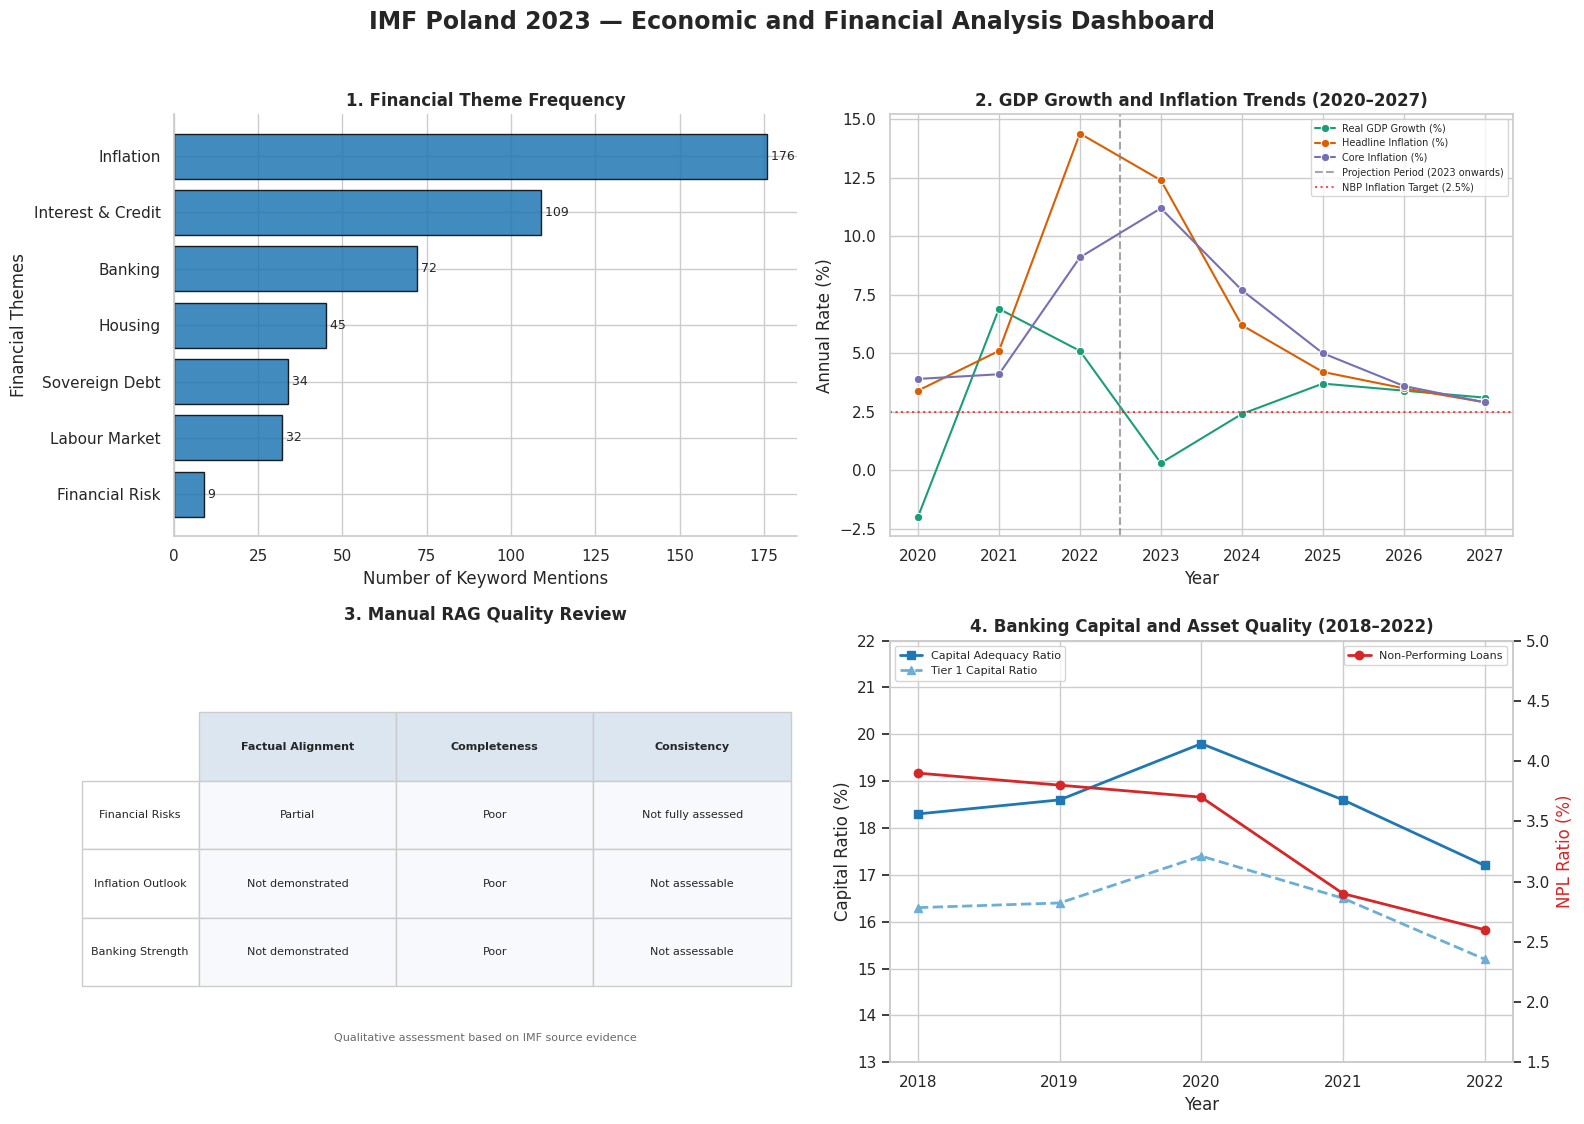

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

macro_trends = pd.DataFrame({
    "Year": [2020, 2021, 2022, 2023, 2024, 2025, 2026, 2027],
    "Real GDP Growth (%)": [-2.0, 6.9, 5.1, 0.3, 2.4, 3.7, 3.4, 3.1],
    "Headline Inflation (%)": [3.4, 5.1, 14.4, 12.4, 6.2, 4.2, 3.5, 2.9],
    "Core Inflation (%)": [3.9, 4.1, 9.1, 11.2, 7.7, 5.0, 3.6, 2.9]
})

# Convert wide data into long format using pd.melt()
macro_long = pd.melt(
    macro_trends,
    id_vars=["Year"],
    var_name="Indicator",
    value_name="Rate"
)


bank_history = pd.DataFrame({
    "Year": [2018, 2019, 2020, 2021, 2022],
    "CAR (%)": [18.3, 18.6, 19.8, 18.6, 17.2],
    "Tier 1 (%)": [16.3, 16.4, 17.4, 16.5, 15.2],
    "NPL Ratio (%)": [3.9, 3.8, 3.7, 2.9, 2.6]
})


review_df = pd.read_csv(
    "poland_rag_final_evaluation.csv"
)

criteria = [
    "Factual Alignment",
    "Completeness",
    "Consistency"
]

question_labels = [
    "Financial Risks",
    "Inflation Outlook",
    "Banking Strength"
]

review_table = review_df[criteria].fillna("Not assessed")


fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11)
)

fig.suptitle(
    "IMF Poland 2023 — Economic and Financial Analysis Dashboard",
    fontsize=17,
    fontweight="bold",
    y=1.02
)


# PANEL 1 — Financial Theme Frequency

ax1 = axes[0, 0]

theme_sorted = theme_df.sort_values(
    by="Mentions",
    ascending=True
)

ax1.barh(
    theme_sorted["Theme"],
    theme_sorted["Mentions"],
    color="#1f77b4",
    edgecolor="black",
    alpha=0.85
)

ax1.set_title(
    "1. Financial Theme Frequency",
    fontweight="bold"
)

ax1.set_xlabel("Number of Keyword Mentions")
ax1.set_ylabel("Financial Themes")

# Display mention counts on each bar
for i, count in enumerate(theme_sorted["Mentions"]):
    ax1.text(
        count,
        i,
        f" {count}",
        va="center",
        fontsize=9
    )

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)



# PANEL 2 — GDP Growth And Inflation Trends

ax2 = axes[0, 1]

palette = {
    "Headline Inflation (%)": "#d95f02",
    "Core Inflation (%)": "#7570b3",
    "Real GDP Growth (%)": "#1b9e77"
}

sns.lineplot(
    data=macro_long,
    x="Year",
    y="Rate",
    hue="Indicator",
    marker="o",
    palette=palette,
    ax=ax2
)


ax2.axvline(
    x=2022.5,
    color="grey",
    linestyle="--",
    alpha=0.7,
    label="Projection Period (2023 onwards)"
)

ax2.axhline(
    y=2.5,
    color="red",
    linestyle=":",
    alpha=0.7,
    label="NBP Inflation Target (2.5%)"
)

ax2.set_title(
    "2. GDP Growth and Inflation Trends (2020–2027)",
    fontweight="bold"
)

ax2.set_xlabel("Year")
ax2.set_ylabel("Annual Rate (%)")
ax2.set_xticks(macro_trends["Year"])
ax2.legend(fontsize=7, loc="upper right")



# PANEL 3 — Manual RAG Quality Review

ax3 = axes[1, 0]
ax3.axis("off")

table = ax3.table(
    cellText=review_table.values,
    rowLabels=question_labels,
    colLabels=criteria,
    cellLoc="center",
    rowLoc="center",
    loc="center",
    bbox=[0.04, 0.18, 0.95, 0.65]
)

table.auto_set_font_size(False)
table.set_fontsize(8)


for (row, col), cell in table.get_celld().items():

    if row == 0:
        cell.set_facecolor("#dce6f1")
        cell.set_text_props(weight="bold")

    elif col >= 0:
        cell.set_facecolor("#f7f9fc")

    cell.set_edgecolor("#cccccc")

ax3.set_title(
    "3. Manual RAG Quality Review",
    fontweight="bold",
    pad=15
)

ax3.text(
    0.5,
    0.05,
    "Qualitative assessment based on IMF source evidence",
    transform=ax3.transAxes,
    ha="center",
    fontsize=8,
    color="dimgray"
)



# PANEL 4 — Banking Capital And Asset Quality

ax4 = axes[1, 1]

ax4_twin = ax4.twinx()

ax4.plot(
    bank_history["Year"],
    bank_history["CAR (%)"],
    marker="s",
    linewidth=2,
    color="#1f77b4",
    label="Capital Adequacy Ratio"
)

ax4.plot(
    bank_history["Year"],
    bank_history["Tier 1 (%)"],
    marker="^",
    linestyle="--",
    linewidth=2,
    color="#6baed6",
    label="Tier 1 Capital Ratio"
)

ax4_twin.plot(
    bank_history["Year"],
    bank_history["NPL Ratio (%)"],
    marker="o",
    linewidth=2,
    color="#d62728",
    label="Non-Performing Loans"
)

ax4.set_title(
    "4. Banking Capital and Asset Quality (2018–2022)",
    fontweight="bold"
)

ax4.set_xlabel("Year")
ax4.set_ylabel("Capital Ratio (%)")
ax4_twin.set_ylabel("NPL Ratio (%)", color="#d62728")

ax4.set_xticks(bank_history["Year"])
ax4.set_ylim(13, 22)
ax4_twin.set_ylim(1.5, 5)

ax4.legend(
    loc="upper left",
    fontsize=8
)

ax4_twin.legend(
    loc="upper right",
    fontsize=8
)

ax4_twin.grid(False)

plt.tight_layout()

plt.savefig(
    "poland_imf_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



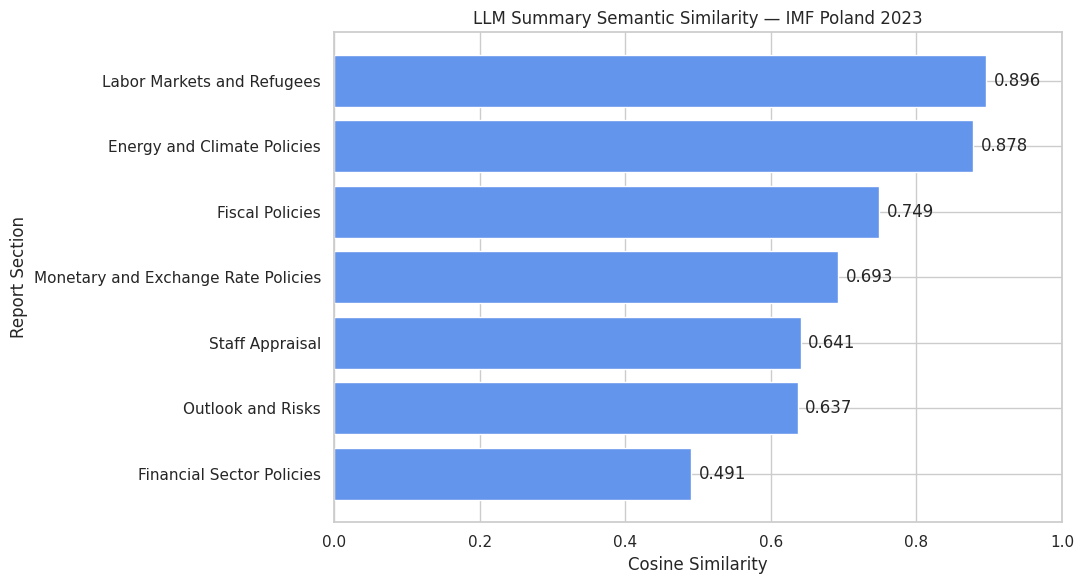

In [30]:
# Summary semantic similarity comparison

plt.figure(figsize=(11, 6))

plot_df = evaluation_df.sort_values(
    "Semantic Similarity",
    ascending=True
)

plt.barh(
    plot_df["Section"],
    plot_df["Semantic Similarity"],
    color="cornflowerblue"
)

plt.xlabel("Cosine Similarity")
plt.ylabel("Report Section")
plt.title("LLM Summary Semantic Similarity — IMF Poland 2023")
plt.xlim(0, 1)

for i, value in enumerate(plot_df["Semantic Similarity"]):
    plt.text(value + 0.01, i, f"{value:.3f}", va="center")

plt.tight_layout()

plt.savefig(
    "poland_summary_similarity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
# Validate generated project outputs

import os

required_files = [
    "poland_cleaned_text.txt",
    "poland_chunks.json",
    "poland_section_summaries.json",
    "poland_executive_summary.json",
    "poland_summary_evaluation.csv",
    "poland_theme_counts.csv",
    "poland_financial_data.json",
    "poland_faiss.index",
    "poland_rag_evaluation.csv",
    "poland_imf_dashboard.png",
    "poland_summary_similarity.png"
]

print("FINAL PROJECT VALIDATION\n")

for filename in required_files:
    status = "PASS" if os.path.isfile(filename) else "FAIL"
    print(f"{filename}: {status}")

print("\nReport Pages:", len(cleaned_pages))
print("Text Chunks:", len(chunks))
print("FAISS Indexed Chunks:", index.ntotal)
print("Section Summaries:", len(section_summaries))

print(
    "All Summaries Under 100 Words:",
    all(len(summary.split()) < 100
        for summary in section_summaries.values())
)

print(
    "FAISS Matches Chunks:",
    index.ntotal == len(chunks)
)

FINAL PROJECT VALIDATION

poland_cleaned_text.txt: PASS
poland_chunks.json: PASS
poland_section_summaries.json: PASS
poland_executive_summary.json: PASS
poland_summary_evaluation.csv: PASS
poland_theme_counts.csv: PASS
poland_financial_data.json: PASS
poland_faiss.index: PASS
poland_rag_evaluation.csv: PASS
poland_imf_dashboard.png: PASS
poland_summary_similarity.png: PASS

Report Pages: 87
Text Chunks: 201
FAISS Indexed Chunks: 201
Section Summaries: 7
All Summaries Under 100 Words: True
FAISS Matches Chunks: True
